# Week 1 — Exploratory Data Analysis
## Voice-based screening of Parkinson's disease

**Dataset:** UCI Parkinson's Disease Classification (Sakar et al., 2018) — https://archive.ics.uci.edu/dataset/470/parkinson+s+disease+classification

**Goal of this notebook (Week 1 only):** understand the data before any modelling.
We check: size and structure, the target, the subjects, data quality (missing values, duplicates, scales, outliers),
redundancy between features, and a first relevance ranking. **No model is trained here** — the baseline comes in Week 2.

> Download `pd_speech_features.csv` from the UCI page (inside the `.rar`) and put it in `data/raw/`.

### Running on Google Colab
Locally this cell does nothing. On Colab it clones the project repo so that the relative paths (`../data/...`, `../results/...`) work.
**Set `REPO_URL` to your group's GitHub repo** (it must be public).

In [1]:
import os, sys, subprocess

REPO_URL = "https://github.com/AA-ESILV/ML-FINALPROJECT-pd-voice-screening.git"

if "google.colab" in sys.modules:
    repo_dir = "/content/" + REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
    if not os.path.isdir(repo_dir):
        subprocess.run(["git", "clone", "-q", REPO_URL, repo_dir], check=True)
    os.chdir(repo_dir + "/notebooks")
    print("Working directory:", os.getcwd())

Working directory: /content/ML-FINALPROJECT-pd-voice-screening/notebooks


### ▶ Setup — works on your computer **and** in Google Colab
In Colab, this cell clones the project repo (data included) and moves into `notebooks/`.
If the repo is not set or is private, it asks you to upload `pd_speech_features.csv` instead.
On your own computer it does nothing.

In [2]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/<your-username>/pd-voice-screening.git"   # <- put your repo URL here (public repo)
RAW_NAME = "pd_speech_features.csv"

if "google.colab" in sys.modules:
    repo_dir = Path("/content") / REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
    if "<your-username>" not in REPO_URL and not repo_dir.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(repo_dir)], check=False)
    if (repo_dir / "notebooks").exists():
        os.chdir(repo_dir / "notebooks")
    else:  # no repo available: build the folders and upload the CSV by hand
        work = Path("/content/project")
        for d in ["notebooks", "data/raw", "data/processed", "results"]:
            (work / d).mkdir(parents=True, exist_ok=True)
        os.chdir(work / "notebooks")
        raw = work / "data" / "raw" / RAW_NAME
        if not raw.exists():
            from google.colab import files
            print(f"Please upload {RAW_NAME} (UCI dataset 470).")
            uploaded = files.upload()
            raw.write_bytes(next(iter(uploaded.values())))

Path("../results").mkdir(exist_ok=True)
print("Working directory:", Path.cwd())

Please upload pd_speech_features.csv (UCI dataset 470).


Saving pd_speech_features.csv to pd_speech_features.csv
Working directory: /content/project/notebooks


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RANDOM_STATE = 42

## 1. Load the data

In [4]:
path = "../data/raw/pd_speech_features.csv"
df = pd.read_csv(path)
# The original UCI file has an extra first line with feature-group names: skip it if present
if df.columns[0] != "id":
    df = pd.read_csv(path, header=1)

print("Shape:", df.shape)
df.iloc[:5, :8]

Shape: (756, 755)


,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses
0,0,1,0.85247,0.71826,0.57227,240,239,0.008064
1,0,1,0.76686,0.69481,0.53966,234,233,0.008258
2,0,1,0.85083,0.67604,0.58982,232,231,0.008340
3,1,0,0.41121,0.79672,0.59257,178,177,0.010858
4,1,0,0.32790,0.79782,0.53028,236,235,0.008162


## 2. Structure: recordings vs subjects
Each row is **one recording**, not one person. The `id` column identifies the subject.

In [5]:
per_subject = df.groupby("id").size()
print("Number of subjects:", df["id"].nunique())
print("Recordings per subject:", per_subject.value_counts().to_dict())
print("Label constant within each subject:", (df.groupby("id")["class"].nunique() == 1).all())

Number of subjects: 252
Recordings per subject: {3: 252}
Label constant within each subject: True


**Observation:** 252 subjects × 3 recordings = 756 rows, and the label never changes inside a subject.
→ The three recordings of a person are *not* independent samples. Splitting must be done **by subject** (Lesson 1: duplicates / related observations across splits = leakage).

## 3. Feature groups and types

In [6]:
X = df.drop(columns=["id", "class"])
y = df["class"]

# Column ranges of each feature family, as documented by the dataset authors
groups = {"Baseline": (2, 23), "Intensity": (23, 26), "Formant": (26, 30), "Bandwidth": (30, 34),
          "Vocal fold": (34, 56), "MFCC": (56, 140), "Wavelet": (140, 322), "TQWT": (322, 754)}
group_of = {"gender": "Demographic"}
for g, (a, b) in groups.items():
    for c in df.columns[a:b]:
        group_of[c] = g
group_of = pd.Series(group_of)

print(group_of.value_counts())
print("\nDtypes:", X.dtypes.value_counts().to_dict())

TQWT           432
Wavelet        182
MFCC            84
Vocal fold      22
Baseline        21
Bandwidth        4
Formant          4
Intensity        3
Demographic      1
Name: count, dtype: int64

Dtypes: {dtype('float64'): 749, dtype('int64'): 4}


## 4. Target and subjects

In [7]:
subj = df.groupby("id").agg(cls=("class", "first"), gender=("gender", "first"))
print("Recordings per class:", y.value_counts().to_dict())
print("Subjects per class:  ", subj["cls"].value_counts().to_dict())
ratio = (y == 1).sum() / (y == 0).sum()
print(f"Imbalance ratio (majority/minority): {ratio:.2f} : 1")
print(f"Majority-class accuracy: {(y == 1).mean():.3f}")
pd.crosstab(subj["cls"].map({0: "Healthy", 1: "PD"}), subj["gender"].map({0: "Female", 1: "Male"}))

Recordings per class: {1: 564, 0: 192}
Subjects per class:   {1: 188, 0: 64}
Imbalance ratio (majority/minority): 2.94 : 1
Majority-class accuracy: 0.746


gender,Female,Male
cls,,
Healthy,41,23
PD,81,107


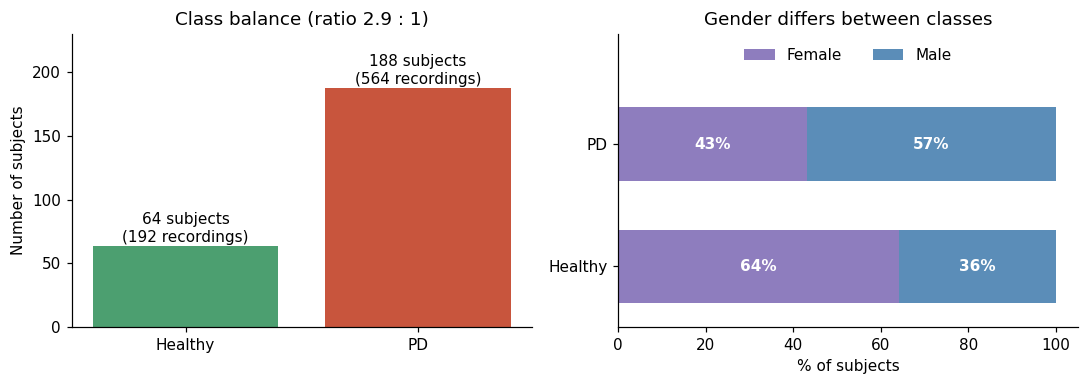

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
counts = subj["cls"].map({0: "Healthy", 1: "PD"}).value_counts()[["Healthy", "PD"]]
axes[0].bar(counts.index, counts.values, color=["#4C9F70", "#C8553D"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 3, f"{v} subjects\n({3*v} recordings)", ha="center")
axes[0].set_ylim(0, 230); axes[0].set_title("Class balance (ratio 2.9 : 1)")
axes[0].set_ylabel("Number of subjects")

ct = pd.crosstab(subj["cls"].map({0: "Healthy", 1: "PD"}), subj["gender"].map({0: "Female", 1: "Male"}), normalize="index") * 100
ct.plot(kind="barh", stacked=True, ax=axes[1], color=["#8E7DBE", "#5B8DB8"], width=0.6)
for i, (f, m) in enumerate(ct.values):
    axes[1].text(f / 2, i, f"{f:.0f}%", ha="center", va="center", color="white", weight="bold")
    axes[1].text(f + m / 2, i, f"{m:.0f}%", ha="center", va="center", color="white", weight="bold")
axes[1].set_xlabel("% of subjects"); axes[1].set_ylabel(""); axes[1].set_title("Gender differs between classes")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False); axes[1].set_ylim(-0.5, 1.9)
plt.tight_layout(); plt.savefig("../results/fig1_target_gender.png", bbox_inches="tight"); plt.show()

**Observations:**
- Imbalance 2.9 : 1 → *low* severity in Lesson 3's scale, but accuracy is still misleading: always answering "PD" gives 74.6 %. We will use ROC-AUC, recall, specificity, balanced accuracy.
- Controls are mostly women, patients mostly men → **gender is a confounder**. We must check later that the model does not just learn gender.

## 5. Data quality: missing values, duplicates, constant columns

In [9]:
print("Missing values:", int(df.isna().sum().sum()))
dup = df.drop(columns="id").duplicated(keep=False)
print("Duplicated recordings:", int(df.drop(columns='id').duplicated().sum()), "→ subject ids:", df.loc[dup, "id"].unique().tolist())
print("Constant columns:", int((X.nunique() <= 1).sum()))

Missing values: 0
Duplicated recordings: 1 → subject ids: [37]
Constant columns: 0


**Observations:** no missing values and no constant column → no imputation needed. One recording of subject 37 is duplicated; since both copies belong to the same subject, a subject-level split keeps them together, so it cannot leak.

## 6. Scales, skewness and outliers

In [10]:
std = X.std()
print(f"Smallest std: {std.min():.2e}   Largest std: {std.max():.2e}")
skew = X.skew().abs()
print("Features with |skew| > 2:", int((skew > 2).sum()), "/", X.shape[1])
Z = (X - X.mean()) / X.std()
print("Values with |z| > 5:", int((Z.abs() > 5).sum().sum()), "  recordings containing at least one:", int((Z.abs() > 5).any(axis=1).sum()))

Smallest std: 5.73e-21   Largest std: 5.70e+09
Features with |skew| > 2: 407 / 753
Values with |z| > 5: 2301   recordings containing at least one: 373


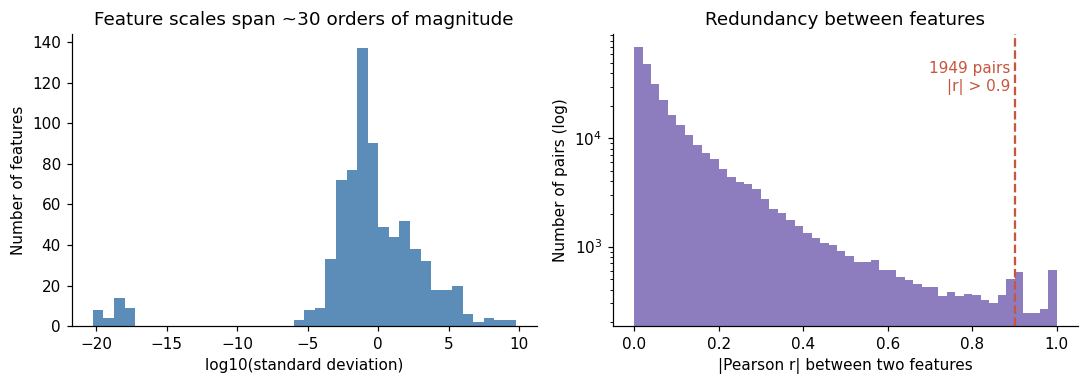

Features involved in at least one |r| > 0.9 pair: 472


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(np.log10(std[std > 0]), bins=40, color="#5B8DB8")
axes[0].set_xlabel("log10(standard deviation)"); axes[0].set_ylabel("Number of features")
axes[0].set_title("Feature scales span ~30 orders of magnitude")

C = np.corrcoef(X.values.T)
iu = np.triu_indices_from(C, 1)
r = np.abs(C[iu])
axes[1].hist(r, bins=50, color="#8E7DBE")
axes[1].set_yscale("log"); axes[1].axvline(0.9, color="#C8553D", ls="--")
axes[1].text(0.89, axes[1].get_ylim()[1] * 0.3, f"{(r > 0.9).sum()} pairs\n|r| > 0.9", ha="right", color="#C8553D")
axes[1].set_xlabel("|Pearson r| between two features"); axes[1].set_ylabel("Number of pairs (log)")
axes[1].set_title("Redundancy between features")
plt.tight_layout(); plt.savefig("../results/fig2_scale_redundancy.png", bbox_inches="tight"); plt.show()

hi = set()
for i, j in zip(*np.where(np.triu(np.abs(C), 1) > 0.9)):
    hi.update([i, j])
print("Features involved in at least one |r| > 0.9 pair:", len(hi))

**Observations:**
- Scales differ enormously (some TQWT means are ~1e-20, some entropies ~1e10) → **standardization is mandatory** for logistic regression, kNN and SVM (Lesson 1). Trees don't need it.
- Many features are strongly skewed and ~half of the recordings contain an extreme value. These are signal-derived measures, so extreme ≠ error (*Outlier ≠ Error*, Lesson 1): we keep them and will compare `StandardScaler` with a log/robust alternative in Week 2 if needed.
- Strong redundancy: 1,949 pairs with |r| > 0.9 → a univariate filter would pick near-copies; mRMR or L1 selection should do better (Lab 4).

## 7. Are recordings of the same person similar? (leakage risk)
For each recording, we look for its nearest neighbour among the other 755 (after standardization).

Nearest neighbour is a recording of the SAME person: 67.9%
Expected by chance: 0.3%


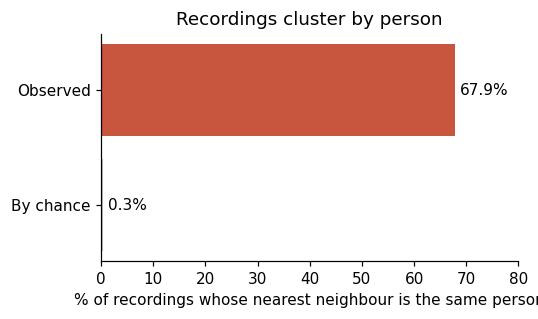

In [12]:
Xs = StandardScaler().fit_transform(X)        # EDA only: no model is evaluated here
nn = NearestNeighbors(n_neighbors=2).fit(Xs)
_, idx = nn.kneighbors(Xs)
same = (df["id"].values[idx[:, 1]] == df["id"].values).mean()
print(f"Nearest neighbour is a recording of the SAME person: {same:.1%}")
print(f"Expected by chance: {2/755:.1%}")

fig, ax = plt.subplots(figsize=(5, 3))
ax.barh(["By chance", "Observed"], [2/755*100, same*100], color=["#BBBBBB", "#C8553D"])
for i, v in enumerate([2/755*100, same*100]):
    ax.text(v + 1, i, f"{v:.1f}%", va="center")
ax.set_xlim(0, 80); ax.set_xlabel("% of recordings whose nearest neighbour is the same person")
ax.set_title("Recordings cluster by person")
plt.tight_layout(); plt.savefig("../results/fig3_same_subject.png", bbox_inches="tight"); plt.show()

**Observation:** 68 % vs 0.3 % by chance. A random recording-level split would let a kNN "recognise the voice" instead of the disease → **`StratifiedGroupKFold` with `groups=id`** is required.

## 8. First look at relevance (filter scores)
To avoid counting each person three times, we average the three recordings per subject, then compute mutual information (MI) and the univariate ROC-AUC of each feature.
*This is exploration only: in Week 3 the selection will be done inside the CV pipeline (Lab 4, Q5).*

In [13]:
S = df.groupby("id").mean()
ys = S["class"].astype(int)
Xsub = S.drop(columns="class")

mi = pd.Series(mutual_info_classif(Xsub, ys, random_state=RANDOM_STATE), index=Xsub.columns)
auc = Xsub.apply(lambda c: roc_auc_score(ys, c))
auc = (auc - 0.5).abs() + 0.5          # direction-free AUC
scores = pd.DataFrame({"group": group_of, "MI": mi, "AUC": auc})
print("Features with MI = 0:", int((mi == 0).sum()))
scores.sort_values("MI", ascending=False).head(10).round(3)

Features with MI = 0: 152


,group,MI,AUC
std_9th_delta,MFCC,0.141,0.764
std_9th_delta_delta,MFCC,0.135,0.787
GQ_std_cycle_open,Vocal fold,0.131,0.675
std_8th_delta_delta,MFCC,0.128,0.780
tqwt_entropy_shannon_dec_12,TQWT,0.125,0.763
std_delta_delta_log_energy,MFCC,0.124,0.798
std_4th_delta,MFCC,0.119,0.679
std_12th_delta_delta,MFCC,0.116,0.739
std_6th_delta_delta,MFCC,0.110,0.768
std_8th_delta,MFCC,0.109,0.767


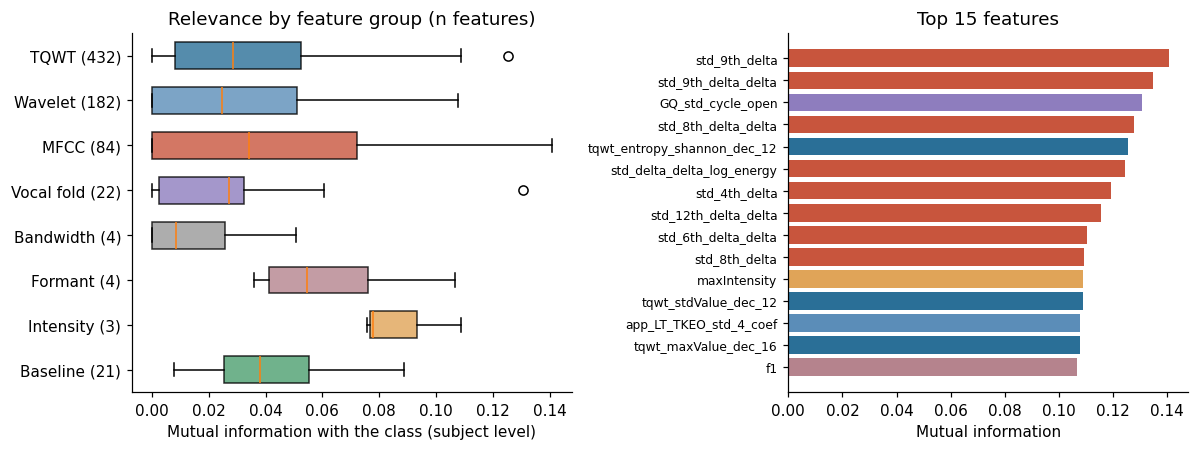

Groups in the top-50 by MI: {'TQWT': 21, 'MFCC': 18, 'Wavelet': 7, 'Vocal fold': 1, 'Intensity': 1, 'Formant': 1, 'Baseline': 1}


In [14]:
order = ["Baseline", "Intensity", "Formant", "Bandwidth", "Vocal fold", "MFCC", "Wavelet", "TQWT"]
colors = dict(zip(order, ["#4C9F70", "#E0A458", "#B5838D", "#999999", "#8E7DBE", "#C8553D", "#5B8DB8", "#2A6F97"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})

data = [scores.loc[scores.group == g, "MI"] for g in order]
bp = axes[0].boxplot(data, vert=False, patch_artist=True, widths=0.6)
for patch, g in zip(bp["boxes"], order):
    patch.set_facecolor(colors[g]); patch.set_alpha(0.8)
axes[0].set_yticks(range(1, len(order) + 1))
axes[0].set_yticklabels([f"{g} ({(scores.group == g).sum()})" for g in order])
axes[0].set_xlabel("Mutual information with the class (subject level)")
axes[0].set_title("Relevance by feature group (n features)")

top = scores.sort_values("MI", ascending=False).head(15)[::-1]
axes[1].barh(top.index, top["MI"], color=[colors[g] for g in top.group])
axes[1].set_xlabel("Mutual information"); axes[1].set_title("Top 15 features")
axes[1].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig("../results/fig4_relevance.png", bbox_inches="tight"); plt.show()

print("Groups in the top-50 by MI:", scores.sort_values("MI", ascending=False).head(50).group.value_counts().to_dict())

**Observations:**
- No single feature is strong: best univariate AUC ≈ 0.80, best MI ≈ 0.14 → the signal is spread over many weak features, so combining them (multivariate models) should help.
- The top features are mostly MFCC derivatives (std of deltas) and TQWT sub-bands, which matches the dataset paper's claim that TQWT features are useful.
- 153 features have MI = 0 and many others are redundant → feature selection is likely to remove a large share of the 753 features without loss.

## 9. Summary of Week 1 EDA → decisions for Week 2

| Finding | Decision |
|---|---|
| 252 subjects × 3 recordings, recordings of a person are near-duplicates | Split by subject: held-out test = 20 % of subjects; `StratifiedGroupKFold(5)` with `groups=id` |
| Imbalance 2.9 : 1, majority accuracy 74.6 % | Metrics: ROC-AUC (main), PD recall, specificity, balanced accuracy; `class_weight="balanced"` |
| No missing values, 1 duplicate (same subject) | No imputation; keep the duplicate |
| Scales over ~30 orders of magnitude, strong skew | `StandardScaler` inside the `Pipeline` |
| 1,949 pairs with \|r\| > 0.9, 153 features with MI = 0 | Feature selection in Week 3 (MI filter, mRMR, RFE, L1), always inside CV |
| Gender confounded with class | Report per-gender recall; test a model without `gender` |
